# CODE 3.3 — Evaluate and explain clustering
**IOTG-64 / IOTG-68 · Beginner notebook**

Run after notebook 01, in the same stage configured in `experiment_config.json`.
The pilot chooses finalists using geometry only. The full stage freezes the primary model
**before** the external-label cells below execute.

This notebook produces measured comparison tables, plots, cluster composition and a short generated
analysis. Outputs appear only when you run with the actual package; no real-data metrics are fabricated.


## 1. What should each metric tell us?
| Metric | Needs true labels? | Interpretation |
|---|---|---|
| Silhouette | No | −1 to 1; higher means tighter, more separated groups in the chosen geometry |
| Davies–Bouldin | No | Lower indicates less overlap relative to cluster spread |
| Calinski–Harabasz | No | Higher indicates larger between-cluster relative to within-cluster dispersion |
| Mean squared distance | No | Compactness around learned centers; compare only within the same scaling/population |
| ARI | Yes, after fitting/selection | 1 = identical partitions; near 0 = chance-level agreement; can be negative |
| NMI | Yes, after fitting/selection | 0–1 association between partitions; not corrected for chance |

For silhouette, \(s(i)=(b(i)-a(i))/\max(a(i),b(i))\), where a is average distance to
the same cluster and b is average distance to the nearest other cluster.
It requires at least two represented clusters and fewer clusters than evaluated rows.
It favors compact separated groups; a security-relevant structure can have a low silhouette.

**Resource policy:** geometry metrics use 10,000 uniform VALIDATION rows; silhouette uses three
fixed 1,500-row subsets of those rows. Full-data silhouette is too expensive (pairwise distances).
The sample standard deviation across repetitions describes sample sensitivity, not a confidence
interval. Samples may overlap. The exact row positions, seeds, represented clusters and scope are saved.
Full-stage ARI/NMI and composition use **all VALIDATION rows**, without feature-distance matrices.


In [1]:
import json
import os
from pathlib import Path

CONFIG_FILE = Path("experiment_config.json")
initial_config = json.loads(CONFIG_FILE.read_text(encoding="utf-8"))
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = str(initial_config["threads"])

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import config_context
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    normalized_mutual_info_score, silhouette_score,
)
from threadpoolctl import threadpool_limits

from clustering_utils import comparison_policy, open_package, read_config, sha256_file, write_json

CFG = read_config(CONFIG_FILE)
STAGE = CFG["stage"]
EXPERIMENT_DIR = Path(CFG["output_root"]) / CFG["experiment_id"]
STAGE_DIR = EXPERIMENT_DIR / STAGE
CACHE = EXPERIMENT_DIR / "cache"
saved_config = json.loads((STAGE_DIR / "configuration.json").read_text(encoding="utf-8"))
if comparison_policy(saved_config) != comparison_policy(CFG):
    raise ValueError("Configuration changed since training; use the archived configuration")
IDENTITY = json.loads((STAGE_DIR / "package_identity.json").read_text(encoding="utf-8"))
run_index = json.loads((STAGE_DIR / "run_index.json").read_text(encoding="utf-8"))
cache_identity = json.loads((CACHE / "cache_identity.json").read_text(encoding="utf-8"))
if cache_identity["identity"] != IDENTITY:
    raise ValueError("The evaluation cache is from a different population")
for item in run_index:
    if sha256_file(STAGE_DIR / item["run_id"] / "model.joblib") != item["model_sha256"]:
        raise ValueError("A saved model changed since training")
print("Evaluating", len(run_index), "models | stage:", STAGE)


Evaluating 2 models | stage: full


## 2. Internal evaluation — no ground-truth labels
For every candidate, load the same cached validation features and final cluster assignments.
`working_memory=64` asks scikit-learn to compute pairwise distances in chunks of roughly that
many MiB. It does not cap the whole Python process.

An undefined score is saved as JSON `null` / CSV empty, with a reason. Never replace undefined
scores with zero or hide a collapsed one-cluster fit. `requested_k` and `observed_clusters` can differ.


In [2]:
internal_rows, silhouette_details = [], []
with threadpool_limits(limits=CFG["threads"]), config_context(working_memory=64):
    for item in run_index:
        run_id, scaling = item["run_id"], item["scaling"]
        run_dir = STAGE_DIR / run_id
        model = joblib.load(run_dir / "model.joblib")["estimator"]
        X = np.load(CACHE / f"VALIDATION_{scaling}.npy", mmap_mode="r")
        clusters = np.load(run_dir / "VALIDATION_sample_clusters.npy", mmap_mode="r")
        np.testing.assert_array_equal(model.predict(X), clusters)
        observed = len(np.unique(clusters))
        repeat_scores = []
        for repeat in range(CFG["silhouette_repeats"]):
            positions = np.load(CACHE / f"silhouette_positions_{repeat}.npy")
            labels_subset = clusters[positions]
            n_clusters = len(np.unique(labels_subset))
            valid = 2 <= n_clusters < len(positions)
            score = float(silhouette_score(X[positions], labels_subset, metric="euclidean")) if valid else None
            if score is not None and not np.isfinite(score):
                raise ValueError("Non-finite silhouette")
            repeat_scores.append(score)
            silhouette_details.append({"run_id": run_id, "repeat": repeat,
                "rows": len(positions), "represented_clusters": n_clusters, "requested_k": item["k"],
                "score": score, "reason": None if valid else "need 2 <= clusters < rows"})
        usable = [value for value in repeat_scores if value is not None]
        # Same number of repetitions is required for a candidate to be eligible for selection.
        all_repeats_valid = len(usable) == CFG["silhouette_repeats"]
        valid_other = 2 <= observed < len(X)
        difference = X - model.cluster_centers_[clusters]
        counts = np.bincount(clusters, minlength=item["k"])
        row = {"run_id": run_id, "stage": STAGE, "scaling": scaling, "requested_k": item["k"],
               "seed": item["seed"], "unique_fit_rows": item["unique_fit_rows"],
               "fit_seconds": item["fit_seconds"], "geometry_eval_rows": len(X),
               "observed_clusters_in_eval_sample": observed,
               "smallest_cluster_in_eval_sample": int(counts.min()),
               "silhouette_rows_per_repeat": min(len(X), CFG["silhouette_rows"]),
               "silhouette_valid_repeats": len(usable),
               "silhouette_mean": float(np.mean(usable)) if all_repeats_valid else None,
               "silhouette_sample_std": float(np.std(usable, ddof=1)) if len(usable) > 1 else None,
               "davies_bouldin": float(davies_bouldin_score(X, clusters)) if valid_other else None,
               "calinski_harabasz": float(calinski_harabasz_score(X, clusters)) if valid_other else None,
               "sample_mean_squared_distance": float(np.einsum("ij,ij->", difference, difference) / len(X)),
               "selection_eligible": all_repeats_valid,
               "geometry_scope": "fixed uniform VALIDATION sample"}
        if STAGE == "full":
            coverage = json.loads((run_dir / "prediction_coverage.json").read_text())
            row["full_validation_mean_squared_distance"] = coverage["VALIDATION"]["mean_squared_distance"]
            row["observed_clusters_full_validation"] = sum(c > 0 for c in coverage["VALIDATION"]["cluster_counts"])
        internal_rows.append(row)

write_json(STAGE_DIR / "internal_metrics.json", internal_rows)
write_json(STAGE_DIR / "silhouette_sampling_details.json", silhouette_details)
internal = pd.DataFrame(internal_rows)
internal.to_csv(STAGE_DIR / "internal_comparison.csv", index=False)
display(internal[["run_id", "unique_fit_rows", "observed_clusters_in_eval_sample", "silhouette_mean",
                  "silhouette_sample_std", "davies_bouldin", "calinski_harabasz", "fit_seconds"]])


,run_id,unique_fit_rows,observed_clusters_in_eval_sample,silhouette_mean,silhouette_sample_std,davies_bouldin,calinski_harabasz,fit_seconds
0,g3b_standard_k8_seed42,4944968,8,0.432241,0.013217,1.207384,1397.532001,17.827990
1,raw_k4_seed42,4944968,4,0.988735,0.001386,0.596001,81561.343722,12.557584


## 3. Compare K within each scaling, then freeze selection
The selection rule was declared before seeing labels: largest mean sampled VALIDATION silhouette
**within the same scaling**; ties at the printed 6-decimal precision prefer smaller K, then smaller seed.
Davies–Bouldin, CH, cluster sizes and distance are supporting diagnostics, not hidden tie breakers.
If no candidate has valid silhouette repetitions, stop and investigate.

Inertia usually decreases as K increases; this alone does not make a larger K better.
Plots use separate panels because raw and standardized geometries differ.


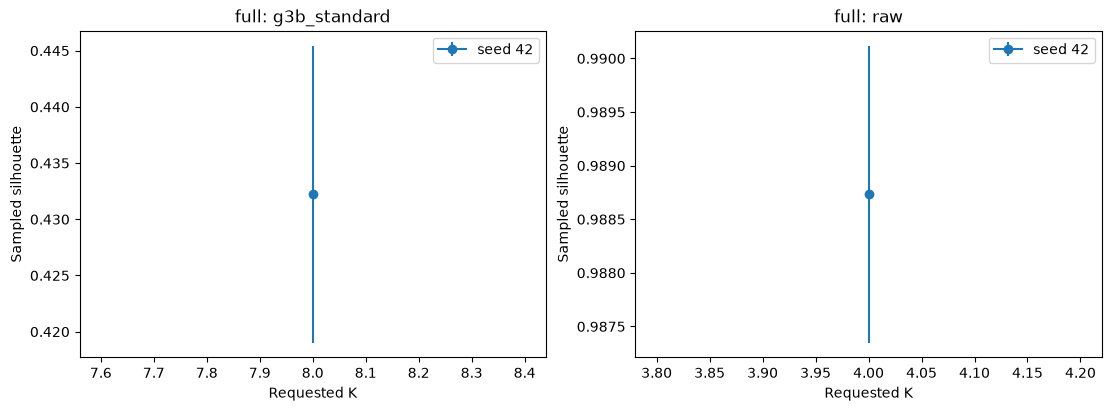

Frozen selection: /home/hembegur/Documents/Swin/cos30049_Inno_Proj/G3B_Clustering_Notebook_Kit/outputs/g3b_clustering_001/full/selection.json


{'identity': {'manifest_relative_path': 'manifest.json',
  'manifest_sha256': '6ab99e86397242e219bfa1f8490d8e03b169ec87a092af80cb3e7aef1e61147b',
  'partitions': {'TRAIN': {'shape': [4944968, 115],
    'dtype': 'float64',
    'metadata_relative_path': 'TRAIN_metadata.npy',
    'metadata_sha256': 'd98a4e6e6058ec476065811a4d30a30682d13952ee0e49af4ffc57a219984080'},
   'VALIDATION': {'shape': [1056372, 115],
    'dtype': 'float64',
    'metadata_relative_path': 'VALIDATION_metadata.npy',
    'metadata_sha256': '2d44c7b63c3c16fb19105ce504b39f6e31fa4145588c07c1d50f2417fad69103'}}},
 'selected_run_id': 'g3b_standard_k8_seed42',
 'primary_scaling': 'g3b_standard',
 'ground_truth_used': False,
 'rule': 'primary scaling fixed in advance; K/seed shortlisted by pilot internal metrics',
 'raw_experiment_role': 'sensitivity analysis, not security-label selection'}

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for axis, scaling in zip(axes, CFG["scalings"]):
    group = internal[internal["scaling"] == scaling]
    for seed, seeded in group.groupby("seed"):
        seeded = seeded.sort_values("requested_k")
        axis.errorbar(seeded["requested_k"], seeded["silhouette_mean"],
                      yerr=seeded["silhouette_sample_std"].fillna(0), marker="o", label=f"seed {seed}")
    axis.set(title=f"{STAGE}: {scaling}", xlabel="Requested K", ylabel="Sampled silhouette")
    axis.legend()
fig.savefig(STAGE_DIR / "silhouette_by_k.png", dpi=160)
plt.show()

def best_within_scaling(frame, scaling):
    eligible = frame[(frame["scaling"] == scaling) & frame["selection_eligible"]].copy()
    if eligible.empty:
        raise ValueError(f"No eligible candidate for {scaling}; inspect collapsed clusters / sample coverage")
    eligible["silhouette_for_tie"] = eligible["silhouette_mean"].round(6)
    return eligible.sort_values(["silhouette_for_tie", "requested_k", "seed"],
                                ascending=[False, True, True]).iloc[0]

if STAGE == "pilot":
    finalists = []
    for scaling in CFG["scalings"]:
        selected = best_within_scaling(internal, scaling)
        finalists.append({"scaling": scaling, "k": int(selected["requested_k"]), "seed": int(selected["seed"])})
    selection = {"identity": IDENTITY, "comparison_policy": comparison_policy(CFG),
                 "finalists": finalists,
                 "rule": "within each scaling, max silhouette rounded to 6 decimals, then smaller K, then seed",
                 "ground_truth_used": False}
    target = STAGE_DIR / "full_plan.json"
else:
    selected = best_within_scaling(internal, "g3b_standard")
    selection = {"identity": IDENTITY, "selected_run_id": selected["run_id"],
                 "primary_scaling": "g3b_standard", "ground_truth_used": False,
                 "rule": "primary scaling fixed in advance; K/seed shortlisted by pilot internal metrics",
                 "raw_experiment_role": "sensitivity analysis, not security-label selection"}
    target = STAGE_DIR / "selection.json"
if target.exists() and json.loads(target.read_text(encoding="utf-8")) != selection:
    raise ValueError("A frozen selection would change. Create a new experiment version instead.")
write_json(target, selection)  # This happens BEFORE any y values are read below.
print("Frozen selection:", target)
display(selection)


## 4. Ground-truth analysis, only after full-stage selection
In pilot stage the following cell deliberately skips labels. Change the JSON stage to `full`, restart,
and run notebook 01 before rerunning this notebook.

For the full stage we compute exact ARI/NMI over all 1,056,372 VALIDATION records. These metrics
compare partitions while ignoring the arbitrary numerical names of clusters. A K>2 partition can
split one binary class into several groups, so modest ARI does not by itself prove useless clustering.
NMI can favor more clusters and is not chance-corrected; interpret it with ARI and composition.

The benign=0 / malicious=1 convention follows the handoff's binary-positive convention. Confirm it
against the package's copied label contract before reporting class names. Unexpected values stop the run.
No cluster→class mapping, accuracy, F1 or 0.5 classifier threshold is imposed.


In [4]:
external_rows = []
if STAGE == "pilot":
    print("Pilot complete. No y values inspected. Set stage=full, restart, run 01, then 02.")
else:
    # Selection already exists on disk. Do not revise it after reading these diagnostic results.
    package, current_identity = open_package(CFG)
    if current_identity != IDENTITY:
        raise ValueError("Package population changed since training")
    _unused_X, y_validation, _unused_metadata = package.load("VALIDATION")
    observed_labels = np.unique(y_validation)
    if set(observed_labels.tolist()) != {CFG["benign_label"], CFG["malicious_label"]}:
        raise ValueError(f"Unexpected binary labels: {observed_labels}. Inspect the copied label contract.")
    malicious_prevalence = float(np.mean(y_validation == CFG["malicious_label"]))
    for item in run_index:
        run_dir = STAGE_DIR / item["run_id"]
        clusters = np.load(run_dir / "VALIDATION_clusters.npy", mmap_mode="r")
        if len(clusters) != len(y_validation):
            raise ValueError("Cluster labels and ground truth do not refer to the same population")
        if sha256_file(run_dir / "VALIDATION_clusters.npy") != json.loads(
                (run_dir / "prediction_coverage.json").read_text())["VALIDATION"]["labels_sha256"]:
            raise ValueError("Saved cluster assignments changed")
        with threadpool_limits(limits=CFG["threads"]):
            ari = float(adjusted_rand_score(y_validation, clusters))
            nmi = float(normalized_mutual_info_score(y_validation, clusters, average_method="arithmetic"))
        # Binary class counts by cluster, streamed with tiny counters rather than a huge DataFrame.
        table = np.zeros((item["k"], 2), dtype=np.int64)
        for start in range(0, len(clusters), CFG["batch_size"]):
            end = min(start + CFG["batch_size"], len(clusters))
            y_chunk, c_chunk = y_validation[start:end], clusters[start:end]
            for column, value in enumerate((CFG["benign_label"], CFG["malicious_label"])):
                table[:, column] += np.bincount(c_chunk[y_chunk == value], minlength=item["k"])
        composition = pd.DataFrame(table, columns=["benign_count", "malicious_count"])
        composition.index.name = "cluster_id"
        composition["total"] = composition.sum(axis=1)
        denominator = composition["total"].replace(0, np.nan)
        composition["malicious_fraction"] = composition["malicious_count"] / denominator
        composition["benign_fraction"] = composition["benign_count"] / denominator
        composition["malicious_lift_vs_validation"] = composition["malicious_fraction"] / malicious_prevalence
        composition.to_csv(run_dir / "cluster_composition_validation.csv")
        external_rows.append({"run_id": item["run_id"], "ari": ari, "nmi": nmi,
            "external_eval_rows": len(y_validation), "external_scope": "entire VALIDATION, post-selection",
            "overall_malicious_fraction": malicious_prevalence})
        print(item["run_id"], "— counts are for ALL VALIDATION rows")
        display(composition)
    write_json(STAGE_DIR / "external_metrics.json", external_rows)
    comparison = internal.merge(pd.DataFrame(external_rows), on="run_id", validate="one_to_one")
    comparison.to_csv(STAGE_DIR / "comparison.csv", index=False)
    display(comparison[["run_id", "silhouette_mean", "davies_bouldin", "ari", "nmi", "external_eval_rows"]])


g3b_standard_k8_seed42 — counts are for ALL VALIDATION rows


,benign_count,malicious_count,total,malicious_fraction,benign_fraction,malicious_lift_vs_validation
cluster_id,,,,,,
0,4279,351918,356197,0.987987,0.012013,1.072713
1,4703,905,5608,0.161377,0.838623,0.175216
2,94,110,204,0.539216,0.460784,0.585457
3,65991,619844,685835,0.903780,0.096220,0.981284
4,3012,0,3012,0.000000,1.000000,0.000000
5,496,0,496,0.000000,1.000000,0.000000
6,68,106,174,0.609195,0.390805,0.661437
7,4792,54,4846,0.011143,0.988857,0.012099


raw_k4_seed42 — counts are for ALL VALIDATION rows


,benign_count,malicious_count,total,malicious_fraction,benign_fraction,malicious_lift_vs_validation
cluster_id,,,,,,
0,82970,948657,1031627,0.919574,0.080426,0.998432
1,89,129,218,0.591743,0.408257,0.642489
2,317,1901,2218,0.857078,0.142922,0.930578
3,59,22250,22309,0.997355,0.002645,1.082884


,run_id,silhouette_mean,davies_bouldin,ari,nmi,external_eval_rows
0,g3b_standard_k8_seed42,0.432241,1.207384,0.007821,0.091792,1056372
1,raw_k4_seed42,0.988735,0.596001,-0.025312,0.008262,1056372


## 5. Explain what the clusters contain
A cluster with 95% malicious records is not especially enriched if the whole validation population
is 97% malicious. Compare against the population prevalence and look at support, not just purity.
`malicious_lift_vs_validation` > 1 means enrichment relative to that population; it is descriptive,
not a calibrated detection probability.

The center profile below shows which feature positions differ most across learned centers in the
primary standardized geometry. It is **not classifier feature importance**. Feature positions must
be mapped to the canonical feature names before making a semantic claim.
Possible structures include traffic volume, regular timing, device differences or attack activity;
only claim the ones supported by the profiles and metadata you actually inspect. This notebook does
not infer device or attack taxonomy from binary y. Those require a separate post-selection join to
the manifest source table, never additional fitting features.


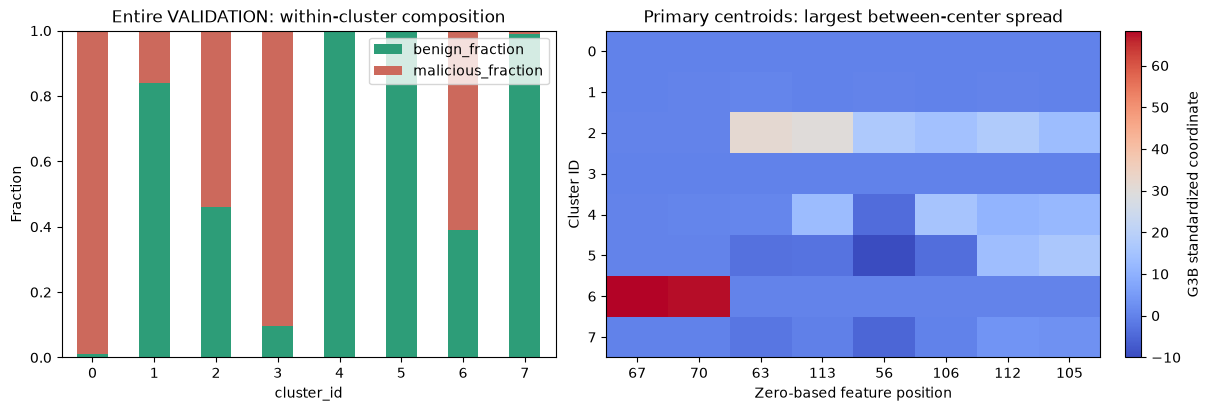

In [5]:
if STAGE == "full":
    primary_id = selection["selected_run_id"]
    primary_dir = STAGE_DIR / primary_id
    composition = pd.read_csv(primary_dir / "cluster_composition_validation.csv", index_col="cluster_id")
    centers = np.load(primary_dir / "cluster_centers.npy")
    np.testing.assert_equal(centers.shape[1], 115)
    spread = np.std(centers, axis=0)
    top_positions = np.argsort(spread)[-8:][::-1]
    profiles = pd.DataFrame(centers, columns=[f"feature_position_{j:03d}" for j in range(centers.shape[1])])
    profiles.index.name = "cluster_id"
    profiles.to_csv(primary_dir / "centroid_profiles_standardized.csv")
    pd.DataFrame({"zero_based_feature_position": np.arange(115), "between_center_std": spread}).to_csv(
        primary_dir / "centroid_spread_by_feature_position.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    composition[["benign_fraction", "malicious_fraction"]].plot.bar(
        stacked=True, ax=axes[0], color=["#2d9d78", "#cc695c"], rot=0)
    axes[0].set(title="Entire VALIDATION: within-cluster composition", ylabel="Fraction", ylim=(0, 1))
    image = axes[1].imshow(centers[:, top_positions], aspect="auto", cmap="coolwarm")
    axes[1].set_xticks(range(len(top_positions)), [str(j) for j in top_positions])
    axes[1].set(title="Primary centroids: largest between-center spread", xlabel="Zero-based feature position",
                ylabel="Cluster ID", yticks=range(len(centers)))
    fig.colorbar(image, ax=axes[1], label="G3B standardized coordinate")
    fig.savefig(STAGE_DIR / "cluster_interpretation.png", dpi=160)
    plt.show()


## 6. Generate a short report from measured values
The generated report states the sampling, the actual scores, and the limits of this experiment.
Add a few sentences mapping feature positions to real names and explaining measured patterns.
Avoid claiming causation, successful attack detection, deployment readiness, or clean generalization
from a silhouette score. N-BaIoT may have duplicate/related rows and device/source effects;
G3B did not deduplicate. Do not silently change the team's splits to address this.

Only seed 42 is run by default. Several silhouette samples do **not** measure model initialization
stability. A stronger extension uses seeds [42,43,44] as a predeclared experiment version, reports
score distributions, and compares assignments on the same validation records using ARI between runs.
That label-free stability ARI is different from ARI against benign/malicious ground truth.


In [7]:
if STAGE == "full":
    primary = comparison.loc[comparison["run_id"] == selection["selected_run_id"]].iloc[0]
    raw = comparison.loc[comparison["scaling"] == "raw"].iloc[0]
    valid_composition = composition[composition["total"] > 0]
    small_clusters = int((valid_composition["total"] < 0.01 * valid_composition["total"].sum()).sum())
    text = f"""# Clustering experiment: measured validation analysis

Primary run: {primary['run_id']}. Protocol: {CFG['protocol_id']}.
All 115 ordered G3B numeric predictors were used. Labels, source identity and device strings
were excluded from fitting. The complete TRAIN population ({int(primary['unique_fit_rows']):,} rows)
was processed for {CFG['full_epochs']} epochs with batch size {CFG['batch_size']}.
Standardization reused G3B's TRAIN-only scaler. TEST was not opened.

## Experiment design and selection
The pilot compared K={CFG['k_values']} for both G3B standardization and raw features, using the
same {CFG['pilot_train_rows']:,}-row uniform TRAIN sample and seed(s) {CFG['seeds']}.
It shortlisted one K per scaling using internal VALIDATION silhouette only. Each finalist was then
trained on all TRAIN rows. Standardized geometry was the primary analysis by prior policy.
The selection was saved before any ground-truth validation labels were inspected.
This is a separate unsupervised protocol proposal, not a classifier macro-F1 result schema.

## Internal geometry
The primary model's silhouette mean was {primary['silhouette_mean']:.6f}, with sample standard
deviation {primary['silhouette_sample_std']:.6f}, over {CFG['silhouette_repeats']} fixed uniform
subsets of {int(primary['silhouette_rows_per_repeat']):,} validation observations.
DBI was {primary['davies_bouldin']:.6f}; CH was {primary['calinski_harabasz']:.6f}, on the same
{int(primary['geometry_eval_rows']):,}-row validation evaluation population used by every run.
Requested K={int(primary['requested_k'])}; full VALIDATION represented
{int(primary['observed_clusters_full_validation'])} clusters.
The raw finalist used K={int(raw['requested_k'])} with silhouette {raw['silhouette_mean']:.6f}.
These geometries differ; this does not establish scale-free superiority of either scaling.
Use pilot/internal_comparison.csv and silhouette_by_k.png for measured K sensitivity.
Pilot and full scores have different fit populations and must not be presented as identical training.

## Post-selection relation to security labels
On all {int(primary['external_eval_rows']):,} VALIDATION records, ARI={primary['ari']:.6f}
and NMI={primary['nmi']:.6f}. These compare cluster partitions with binary labels;
they are not classification accuracy and do not assign benign/malicious names to cluster IDs.
Overall malicious prevalence was {primary['overall_malicious_fraction']:.2%}.
Among nonempty clusters, malicious fractions ranged from
{valid_composition['malicious_fraction'].min():.2%} to {valid_composition['malicious_fraction'].max():.2%}.
There were {small_clusters} nonempty clusters with <1% of validation rows.
Inspect exact counts, enrichment, and centroid profiles before describing separation.

## Limits and interpretation still required
K-Means favors compact Euclidean groups, always assigns a cluster, and does not supply a calibrated
malicious probability. Scaling, outliers, related predictors and device/source effects can dominate.
The full stream used local buffer shuffling rather than a global permutation; order effects remain.
Two epochs are a budget, not evidence of full convergence. Default seed 42 provides no seed stability claim.
Uniform evaluation samples can miss rare groups; sample variation is not a confidence interval.
Binary-label agreement does not establish separation of attack types, unseen devices or future traffic.
G3B preserves duplicates and original splits; this evaluation does not remove leakage/source risks.
The supplied handoff's verification does not by itself prove this receiving machine is TEAM_VERIFIED.

Before submission, map the largest-spread centroid feature positions to canonical feature names,
describe the observed direction and support of at least two clusters, and state whether mixed
clusters suggest device/traffic structure rather than a useful benign/malicious partition.
Do not revise model selection after this post-selection inspection without a new protocol version.
"""
    (STAGE_DIR / "analysis.md").write_text(text, encoding="utf-8")
    write_json(STAGE_DIR / "evaluation_receipt.json", {
        "status": "validation_evaluated", "test_opened": False,
        "primary_run_id": selection["selected_run_id"],
        "internal_feature_rows": int(primary["geometry_eval_rows"]),
        "silhouette_rows_per_repeat": int(primary["silhouette_rows_per_repeat"]),
        "silhouette_repeats": CFG["silhouette_repeats"],
        "external_label_rows": int(primary["external_eval_rows"]),
        "ground_truth_used_for_fit_or_selection": False,
    })
    print(text)
else:
    print("Saved pilot internal comparison and full_plan.json. Full training is the next step.")


# Clustering experiment: measured validation analysis

Primary run: g3b_standard_k8_seed42. Protocol: g3b_unsupervised_v1_proposal.
All 115 ordered G3B numeric predictors were used. Labels, source identity and device strings
were excluded from fitting. The complete TRAIN population (4,944,968 rows)
was processed for 2 epochs with batch size 4096.
Standardization reused G3B's TRAIN-only scaler. TEST was not opened.

## Experiment design and selection
The pilot compared K=[2, 4, 8, 12] for both G3B standardization and raw features, using the
same 100,000-row uniform TRAIN sample and seed(s) [42].
It shortlisted one K per scaling using internal VALIDATION silhouette only. Each finalist was then
trained on all TRAIN rows. Standardized geometry was the primary analysis by prior policy.
The selection was saved before any ground-truth validation labels were inspected.
This is a separate unsupervised protocol proposal, not a classifier macro-F1 result schema.

## Internal geometry
The primary 

## 7. Submission and rerun evidence
After the full stage, retain both notebooks, configuration, exact lock/environment files, pilot
comparison, full models, prediction arrays, logs, full comparison table, figures and the edited analysis.
Use `replay_predictions.py` to independently regenerate full assignments and compare them exactly
with the saved arrays. See `START_HERE.md` for the command.

This notebook reports VALIDATION results. Final TEST evaluation, if the project later authorizes it,
requires a separate frozen protocol; `allow_test=True` is deliberately absent from this kit.

## Official references
- [Silhouette score and valid cluster counts](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [Clustering evaluation, DBI and CH](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)
- [Adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)
- [Normalized mutual information](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html)
